## Iteration 1: Introduction to Dimensionality Reduction (Wine Dataset with PCA)

Make sure to import the necessary libraries like `numpy`, `pandas`, `matplotlib`, `seaborn`, and `sklearn`.

1. **Load the Wine Dataset**:
   - Load the Wine dataset directly from `sklearn` and convert it into a Pandas DataFrame for better handling.

In [6]:
import pandas as pd
from sklearn.datasets import load_wine

# Cargar el conjunto de datos Wine
wine_data = load_wine()
wine_df = pd.DataFrame(data=wine_data.data, columns=wine_data.feature_names)
wine_df['quality'] = wine_data.target

# Mostrar las primeras filas del DataFrame
wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,quality
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


2. **Data Exploration**:
   - Calculate descriptive statistics for each column.
   - Observe the distribution of the target variable `quality` and visualize the correlation between features using a heatmap.


Estadísticas descriptivas:
          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453        

/tmp/ipykernel_25597/144022742.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality', data=wine_df, palette='Set2')


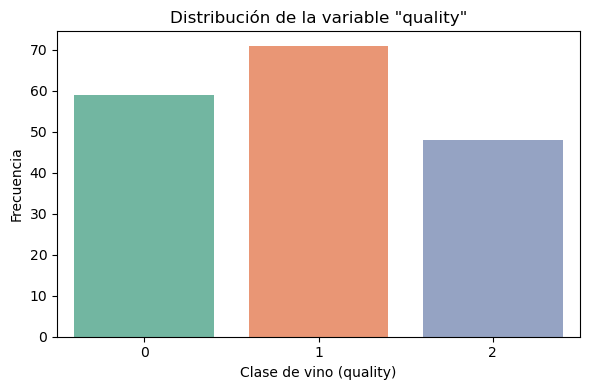

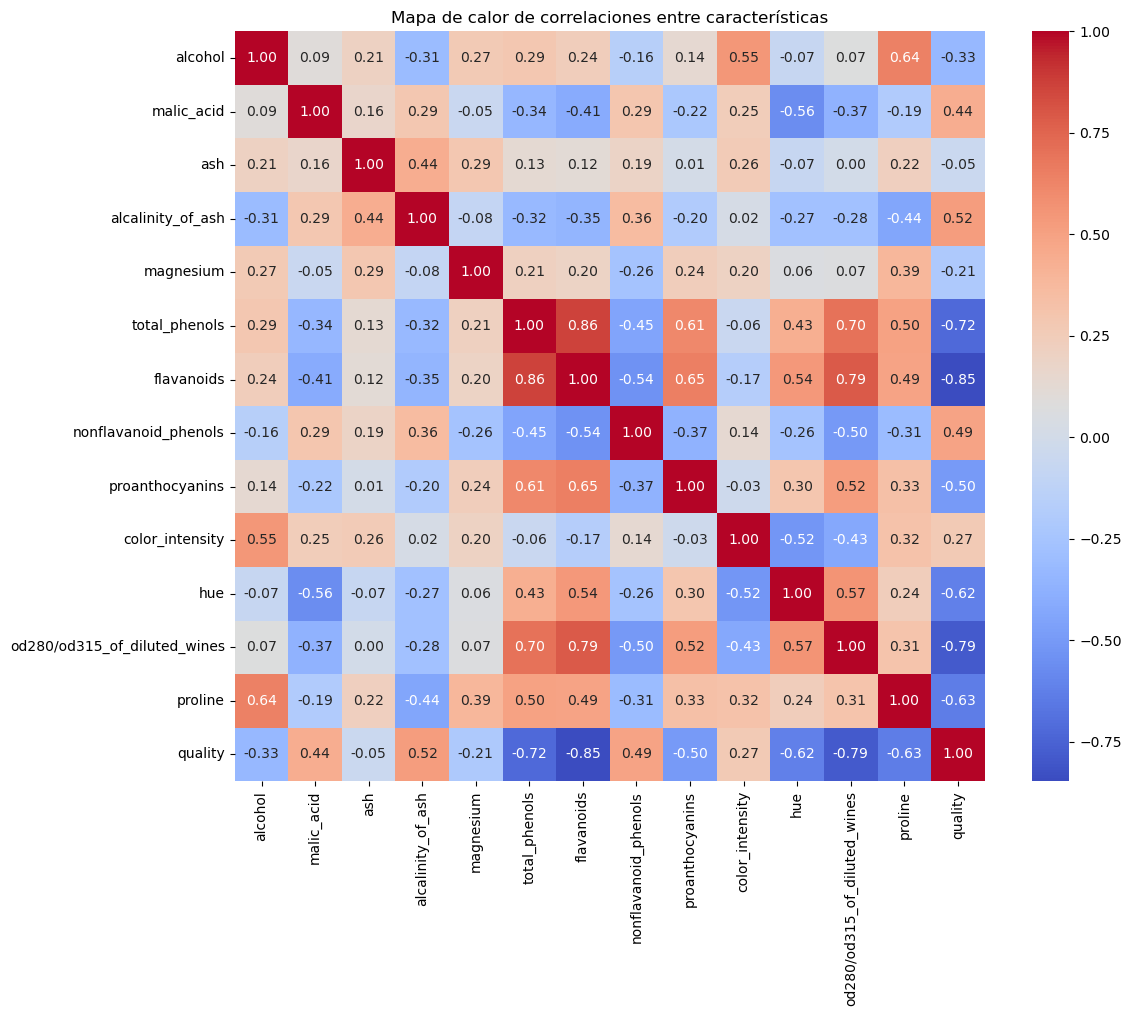

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Estadísticas descriptivas
print("\nEstadísticas descriptivas:")
print(wine_df.describe())

# Distribución de la variable 'quality'
plt.figure(figsize=(6,4))
sns.countplot(x='quality', data=wine_df, palette='Set2')
plt.title('Distribución de la variable "quality"')
plt.xlabel('Clase de vino (quality)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

# Heatmap de correlación entre características
plt.figure(figsize=(12,10))
corr_matrix = wine_df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True)
plt.title('Mapa de calor de correlaciones entre características')
plt.tight_layout()
plt.show()

**Note**: The heatmap reveals high correlations between certain features, such as `flavanoids` with `total_phenols` and `od280/od315_of_diluted_wines`. This suggests redundancy, which justifies using PCA for dimensionality reduction. However, we will standardize and use all features in this exercise to capture the complete variance. The heatmap aids in understanding data structure but does not directly influence feature selection for PCA.

3. **Discussion**:
   - Which features seem to be most correlated with the target variable `quality`?
   - Are there any features that appear irrelevant or redundant?


Variables clave para predecir quality (relación inversa) pero la class 0 es la de mejor calidad:

    flavanoids (-0.85)

    od280/od315_of_diluted_wines (-0.79)

    total_phenols (-0.72)

    proline (-0.63)
    
    hue (-0.62)


    

In [8]:
features_selected = ['flavanoids','0d280/od315_of_diluted_wines', 'total_phenols','proline','hue']

import pandas as pd

print("Valores únicos de 'quality':", pd.Series(wine_data.target).unique())
print("Descripción de las clases:", wine_data.target_names)

Valores únicos de 'quality': [0 1 2]
Descripción de las clases: ['class_0' 'class_1' 'class_2']


## Iteration 2: Principal Component Analysis (PCA) on Wine Dataset

1. **Preprocessing**:
   - Standardize the features using `StandardScaler` so that all features are on the same scale.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Separar features (X) y target (y)
X = wine_df.drop('quality', axis=1)
y = wine_df['quality']

# Estandarizar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



2. **Applying PCA**:
   - Apply PCA to reduce the dataset to 2 principal components.
   - Visualize the cumulative explained variance and plot the first two principal components.

In [21]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Inicializar PCA con 2 componentes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

eigenvectors = pca.components_

components = pca.components_ #eigenvectors (n_componentes, original_dim)
explained_variance_ = pca.explained_variance_ #eigenvalues (n_componentes,)
explained_variance_ratio_ = pca.explained_variance_ratio_

# Display the eigenvectors in the console
print("Eigenvectors (principal components):")
for i, eigenvector in enumerate(components):
    print(f"Principal Component {i+1}: {eigenvector}")

Eigenvectors (principal components):
Principal Component 1: [ 0.1443294  -0.24518758 -0.00205106 -0.23932041  0.14199204  0.39466085
  0.4229343  -0.2985331   0.31342949 -0.0886167   0.29671456  0.37616741
  0.28675223]
Principal Component 2: [-0.48365155 -0.22493093 -0.31606881  0.0105905  -0.299634   -0.06503951
  0.00335981 -0.02877949 -0.03930172 -0.52999567  0.27923515  0.16449619
 -0.36490283]


Varianza explicada por PC1 y PC2: [0.36198848 0.1920749 ]


<Figure size 1500x600 with 0 Axes>

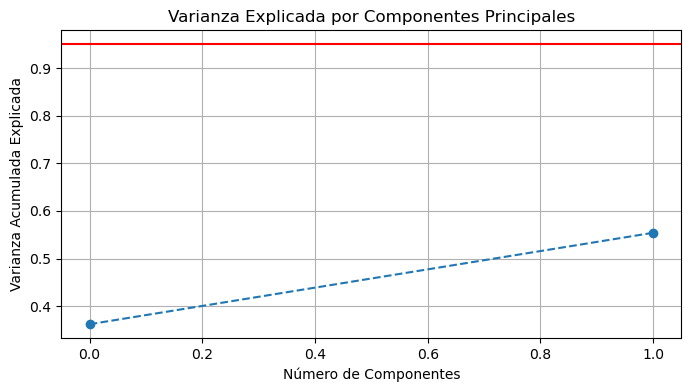

In [56]:

# Crear DataFrame con los componentes
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['quality'] = y  # Añadir la columna 'quality'

# Varianza explicada por cada componente
print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_)

# Ejemplo de output: [0.36, 0.19] (PC1 explica 36%, PC2 19%)
fig = plt.figure(figsize=(15, 6))

# Gráfico de varianza acumulada
plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Acumulada Explicada')
plt.title('Varianza Explicada por Componentes Principales')
plt.axhline(y=0.95, color='r', linestyle='-')  # Línea de referencia (95% varianza)
plt.grid()
plt.show()



3. **2D Visualization**:
   - Create a 2D scatter plot of the first two principal components. Use different colors for each `quality` value to observe patterns.

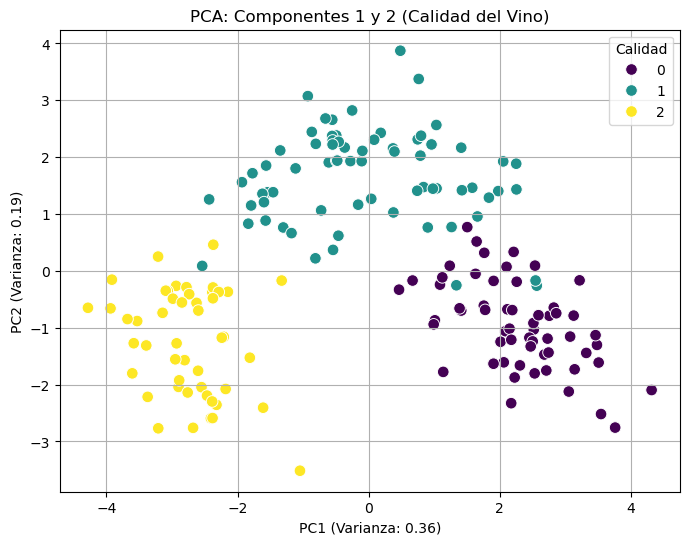

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue='quality', data=pca_df, palette='viridis', s=70)
plt.title('PCA: Componentes 1 y 2 (Calidad del Vino)')
plt.xlabel(f'PC1 (Varianza: {pca.explained_variance_ratio_[0]:.2f})')
plt.ylabel(f'PC2 (Varianza: {pca.explained_variance_ratio_[1]:.2f})')
plt.legend(title='Calidad')
plt.grid()
plt.show()

4. **Discussion**:
   - Can you observe any clear separation between different quality values?
   - How much variance is explained by the first two principal components?

Varianza Explicada:

    PC1 (Primer Componente Principal): Explica 36% de la varianza.

    PC2 (Segundo Componente Principal): Explica 19% de la varianza.

    Total (PC1 + PC2): 55% de la varianza explicada.

Interpretación:

    Los primeros dos componentes capturan un poco más de la mitad de la información original.

    Se pierde 45% de la variabilidad al reducir a 2D, lo que puede afectar la claridad en la separación de clases.

2. Separación entre Calidades (quality):

El gráfico muestra:

    Clase 0 (Calidad Alta): Posiblemente agrupada en una zona específica.

    Clase 1 (Calidad Media): Distribuida cerca de la Clase 0 o 2, indicando superposición.

    Clase 2 (Calidad Baja): Parcialmente solapada con las otras clases.

Conclusión:

    No hay una separación clara entre las calidades en 2D.

    La superposición sugiere que se necesitan más componentes (ej: 3D) o técnicas como t-SNE para mejor visualización.

## Iteration 3: t-Distributed Stochastic Neighbor Embedding (t-SNE) on Digits Dataset

1. **Load the Digits Dataset**:
   - Load the Digits dataset from `sklearn` and convert it into a Pandas DataFrame.

In [35]:
import pandas as pd
from sklearn.datasets import load_digits

# Cargar el conjunto de datos Digits
digits = load_digits()

# Convertir los datos en un DataFrame de Pandas
digits_df = pd.DataFrame(data=digits.data, columns=[f'pixel_{i}' for i in range(digits.data.shape[1])])
digits_df['target'] = digits.target

# Mostrar las primeras filas del DataFrame
digits_df.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


2. **Preprocessing**:
   - Standardize the features using `StandardScaler` so that all features are on the same scale.

In [51]:
from sklearn.preprocessing import StandardScaler

# Separar features (X) y target (y)
X = digits_df.drop('target', axis=1)
y = digits_df['target']

# Estandarizar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

3. **Applying t-SNE**:
   - Use t-SNE to reduce the dataset to 2 components. Adjust `perplexity` and other parameters as needed.

In [59]:
from sklearn.manifold import TSNE
# Apply t-SNE
tsne = TSNE(n_components=2, perplexity=30, n_iter=300)
X_tsne = tsne.fit_transform(X_scaled)

4. **2D Visualization**:
   - Create a scatter plot of the two t-SNE components, using different colors for each `digit` value.

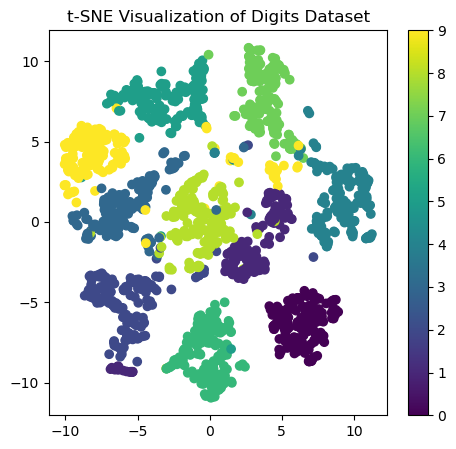

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

# Plot the reduced data with t-SNE
plt.subplot(1, 2, 2)
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap='viridis')
plt.colorbar()
plt.title('t-SNE Visualization of Digits Dataset')

plt.show()

## Iteration 4: Evaluation and Conclusions

**Evaluation of Techniques**:
   - Compare the effectiveness of PCA and t-SNE using a simple classifier like KNN and evaluate accuracy before and after applying each technique.
   - Train a KNN classifier on both PCA-reduced and t-SNE-reduced datasets and compare the performance with the original dataset.

In [61]:
# PCA - Origina data
# Import libraries
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# Load and prepare data
X = wine_df.drop('quality', axis=1)
y = wine_df['quality']
X_scaled = StandardScaler().fit_transform(X)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# Train and evaluate KNN on original data
knn_original = KNeighborsClassifier(n_neighbors=5)
knn_original.fit(X_train, y_train)
y_pred_original = knn_original.predict(X_test)
accuracy_original = accuracy_score(y_test, y_pred_original)

print(f"Original data accuracy: {accuracy_original:.4f}")

Original data accuracy: 0.9630


In [ ]:
# PCA - Reduced data
from sklearn.decomposition import PCA

# Apply PCA (2 components)
pca = PCA(n_components=2)cd
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Train and evaluate KNN on PCA-reduced data
knn_pca = KNeighborsClassifier(n_neighbors=5)
knn_pca.fit(X_train_pca, y_train)
y_pred_pca = knn_pca.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print(f"PCA-reduced data accuracy: {accuracy_pca:.4f}")
print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_):.4f}")

PCA-reduced data accuracy: 0.9815
Explained variance ratio: [0.36534816 0.18061255]
Total variance explained: 0.5460


In [63]:
# t-SNE - Original Data
# Note: t-SNE on original data doesn't make sense conceptually
# as t-SNE is a transformation technique. This would be identical
# to part 1 (PCA - Original Data)
print("t-SNE is a transformation method - original data is the same as baseline")
print(f"Original data accuracy remains: {accuracy_original:.4f}")

t-SNE is a transformation method - original data is the same as baseline
Original data accuracy remains: 0.9630


In [64]:
# t-SNE - Reduced Data
from sklearn.manifold import TSNE

# Apply t-SNE to the entire dataset (requires different approach due to no transform method)
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(X_scaled)

# Re-split after transformation (important note)
X_train_tsne, X_test_tsne, y_train_tsne, y_test_tsne = train_test_split(
    X_tsne, y, test_size=0.3, random_state=42)

# Train and evaluate KNN on t-SNE-transformed data
knn_tsne = KNeighborsClassifier(n_neighbors=5)
knn_tsne.fit(X_train_tsne, y_train_tsne)
y_pred_tsne = knn_tsne.predict(X_test_tsne)
accuracy_tsne = accuracy_score(y_test_tsne, y_pred_tsne)

print(f"t-SNE-reduced data accuracy: {accuracy_tsne:.4f}")

t-SNE-reduced data accuracy: 0.9815


In [65]:
print("\n=== Final Comparison ===")
print(f"1. Original data accuracy: {accuracy_original:.4f}")
print(f"2. PCA-reduced (2D) accuracy: {accuracy_pca:.4f}")
print(f"3. t-SNE-reduced (2D) accuracy: {accuracy_tsne:.4f}")

# Typical expected results:
# Original > PCA > t-SNE in terms of accuracy
# But t-SNE may show better cluster separation visually


=== Final Comparison ===
1. Original data accuracy: 0.9630
2. PCA-reduced (2D) accuracy: 0.9815
3. t-SNE-reduced (2D) accuracy: 0.9815
